In [121]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"

RAW_DIR = (
    DATA_DIR
    / "UrbanEVDataset"
    / "20220901-20230228_station-raw"
)

CHARGE_DIR = RAW_DIR / "charge_5min"

csv_files = list(DATA_DIR.rglob("*.csv"))

print("Total CSV files:", len(csv_files))
print("Dataset directory exists:", RAW_DIR.exists())

Total CSV files: 1703
Dataset directory exists: True


## 2. Dataset Selection and Sampling

To reduce computational complexity while preserving
spatial and temporal patterns, a geographically
concentrated subset of the UrbanEV dataset is selected.

### Study Area Configuration

- Location: Futian area, Shenzhen, China
- Total stations: 100
- Center latitude: 22.54
- Center longitude: 114.05
- Maximum distance from center: 2.14 km
- Time period: December 2022 – February 2023
- Temporal resolution: 5 minutes
- Selection method: Haversine distance

This geographical selection supports regional availability
prediction, interactive map visualization, and nearby
charging station recommendations.

### 2.1. Station Information

Inspect station metadata, including geographical
coordinates and charging capacity.

In [122]:
stations = pd.read_csv(
    RAW_DIR / "station_information.csv"
)

print("Shape:", stations.shape)
print("Columns:", stations.columns.tolist())

display(stations.head())

Shape: (1682, 7)
Columns: ['station_id', 'longitude', 'latitude', 'slow_count', 'fast_count', 'charge_count', 'TAZID']


,station_id,longitude,latitude,slow_count,fast_count,charge_count,TAZID
0,1001,113.784724,22.714121,20,0,20,559
1,1002,113.785002,22.725900,22,0,22,558
2,1003,113.787971,22.735538,6,0,6,558
3,1004,113.788126,22.693449,6,5,11,596
4,1005,113.788126,22.693449,6,5,11,596


### 2.2. Charging Station Data Structure

Inspect individual station time-series files
and identify the available charging variables.

In [123]:
charge_files = sorted(CHARGE_DIR.glob("*.csv"))

print("Station CSV files:", len(charge_files))

sample = pd.read_csv(charge_files[0])

print("Sample file:", charge_files[0].name)
print("Shape:", sample.shape)
print("Columns:", sample.columns.tolist())

display(sample.head(10))

Station CSV files: 1682
Sample file: 1001.csv
Shape: (52128, 11)
Columns: ['time', 'busy', 'idle', 's_price', 'e_price', 'fast_busy', 'fast_idle', 'slow_busy', 'slow_idle', 'duration', 'volume']


,time,busy,idle,s_price,e_price,fast_busy,fast_idle,slow_busy,slow_idle,duration,volume
0,2022-09-01 00:00:00,4.0,16.0,0.47,1.2,0.0,0.0,4.0,16.0,0.000000,0.000000
1,2022-09-01 00:05:00,4.0,16.0,0.47,1.2,0.0,0.0,4.0,16.0,0.000000,0.000000
2,2022-09-01 00:10:00,4.0,16.0,0.47,1.2,0.0,0.0,4.0,16.0,0.000000,0.000000
3,2022-09-01 00:15:00,8.0,12.0,0.47,1.2,0.0,0.0,8.0,12.0,0.083333,0.583333
4,2022-09-01 00:20:00,6.0,14.0,0.47,1.2,0.0,0.0,6.0,14.0,0.083333,0.583333
5,2022-09-01 00:25:00,6.0,14.0,0.47,1.2,0.0,0.0,6.0,14.0,0.083333,0.583333
6,2022-09-01 00:30:00,6.0,14.0,0.47,1.2,0.0,0.0,6.0,14.0,0.083333,0.583333
7,2022-09-01 00:35:00,8.0,12.0,0.47,1.2,0.0,0.0,8.0,12.0,0.083333,0.583333
8,2022-09-01 00:40:00,8.0,12.0,0.47,1.2,0.0,0.0,8.0,12.0,0.083333,0.583333
9,2022-09-01 00:45:00,20.0,0.0,0.47,1.2,0.0,0.0,20.0,0.0,0.000000,0.000000


### 2.3. Geographical Distribution of Charging Stations

The geographical distribution of charging stations
is examined to identify a spatially concentrated
study area in Shenzhen.

Selecting geographically close stations supports
future map visualization and charging station
recommendations.

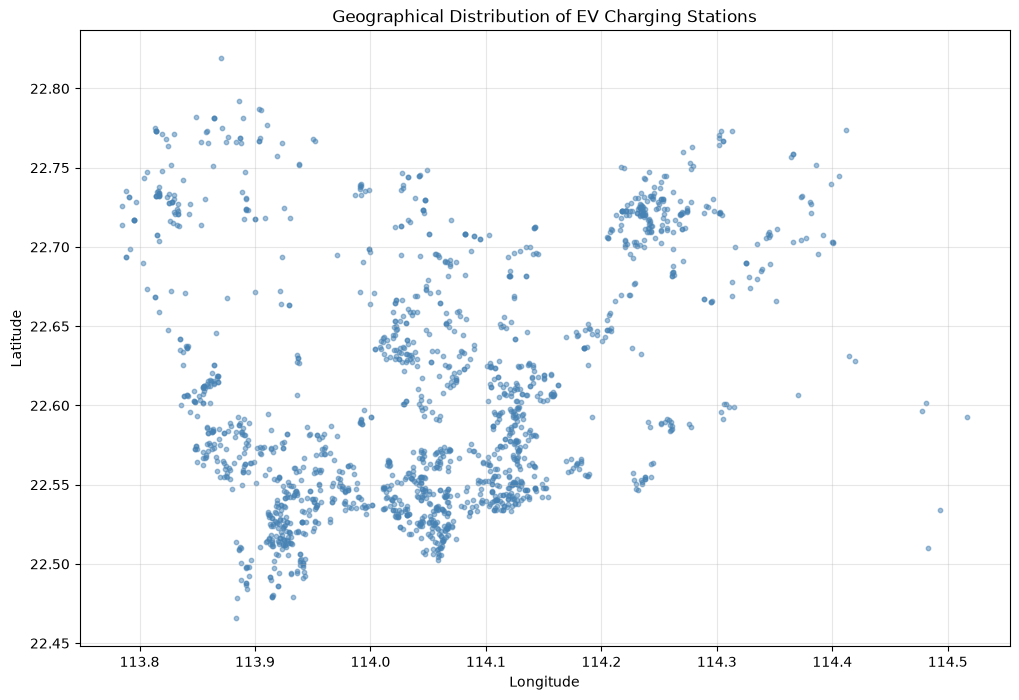

In [124]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

plt.scatter(
    stations["longitude"],
    stations["latitude"],
    s=10,
    alpha=0.5,
    color="steelblue"
)

plt.title("Geographical Distribution of EV Charging Stations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.3)
plt.show()

### 2.4. Geographical Station Selection

A geographically concentrated subset of 100 charging
stations is selected around the Futian area of Shenzhen.

Stations are selected based on their geographical distance
from a fixed central point to support regional availability
prediction and interactive map visualization.

In [125]:
import numpy as np

RAW_DIR = (
    DATA_DIR
    / "UrbanEVDataset"
    / "20220901-20230228_station-raw"
)

CHARGE_DIR = RAW_DIR / "charge_5min"

CENTER_LAT = 22.54
CENTER_LON = 114.05
N_STATIONS = 100

available_ids = {
    int(file.stem)
    for file in CHARGE_DIR.glob("*.csv")
    if file.stem.isdigit()
}

eligible_stations = stations[
    stations["station_id"].isin(available_ids)
].dropna(subset=["latitude", "longitude"]).copy()

# Haversine distance in kilometers
lat = np.radians(eligible_stations["latitude"])
lon = np.radians(eligible_stations["longitude"])

center_lat = np.radians(CENTER_LAT)
center_lon = np.radians(CENTER_LON)

a = (
    np.sin((lat - center_lat) / 2)**2
    + np.cos(center_lat) * np.cos(lat)
    * np.sin((lon - center_lon) / 2)**2
)

eligible_stations["distance_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

selected_stations = eligible_stations.sort_values(
    ["distance_km", "station_id"]
).head(N_STATIONS).copy()

print("Selected stations:", len(selected_stations))
print("Maximum distance (km):",
      round(selected_stations["distance_km"].max(), 2))

display(selected_stations.head(10))

Selected stations: 100
Maximum distance (km): 2.14


,station_id,longitude,latitude,slow_count,fast_count,charge_count,TAZID,distance_km
846,1847,114.051136,22.538613,6,0,6,1062,0.193385
834,1835,114.048537,22.541915,11,0,11,1062,0.260611
847,1848,114.051237,22.537910,6,0,6,1062,0.264855
841,1842,114.050910,22.543973,6,0,6,1061,0.451554
814,1815,114.046011,22.543494,12,0,12,1061,0.564600
789,1790,114.044090,22.540048,5,0,5,227,0.606986
790,1791,114.044090,22.540048,5,0,5,227,0.606986
862,1863,114.054052,22.544005,26,0,26,1061,0.609504
792,1793,114.044260,22.541976,2,0,2,1062,0.629116
795,1796,114.044518,22.543329,3,0,3,1061,0.673790


### 2.5. Visualizing Selected Stations

The selected charging stations are highlighted to
verify the geographical concentration of the study area.

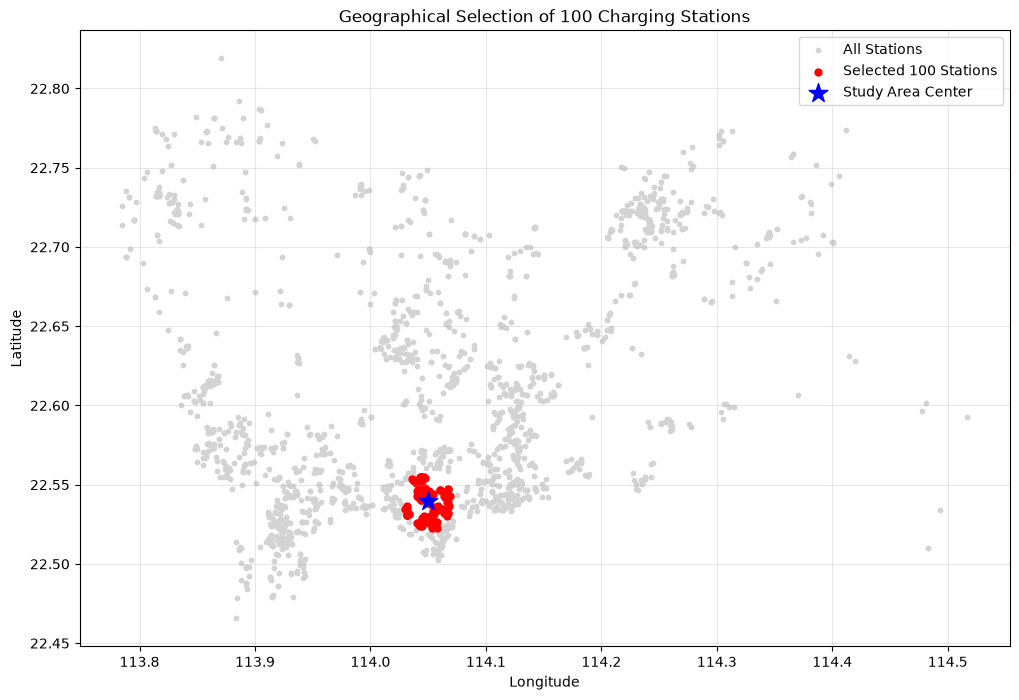

In [126]:
plt.figure(figsize=(12, 8))

plt.scatter(
    stations["longitude"],
    stations["latitude"],
    s=10,
    color="lightgray",
    label="All Stations"
)

plt.scatter(
    selected_stations["longitude"],
    selected_stations["latitude"],
    s=25,
    color="red",
    label="Selected 100 Stations"
)

plt.scatter(
    CENTER_LON,
    CENTER_LAT,
    s=200,
    color="blue",
    marker="*",
    label="Study Area Center"
)

plt.title("Geographical Selection of 100 Charging Stations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 2.6. Saving Selected Stations

Export the selected station metadata to ensure
consistent dataset selection across all team members.

In [127]:
OUTPUT_DIR = ROOT / "outputs" / "tables"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

selected_stations.to_csv(
    OUTPUT_DIR / "selected_stations.csv",
    index=False
)

print("Selected stations saved successfully!")

Selected stations saved successfully!


## 3. Station Availability and Target Distribution

This section investigates charging station availability,
missing observations, target distribution, class imbalance,
and station-level occupancy patterns using the selected
100 charging stations.

In [128]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
import importlib

ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

import data_loader as dl
importlib.reload(dl)

df = dl.load_data().reset_index()

station_info = dl.load_station_info()

df = df.merge(
    station_info,
    on="station_id",
    how="left",
    validate="many_to_one"
)

print("Dataset shape:", df.shape)
print("Number of stations:", df["station_id"].nunique())
print("Start date:", df["time"].min())
print("End date:", df["time"].max())
print("Missing idle values:", df["idle"].isna().sum())

display(df.head())

Dataset shape: (2592000, 19)
Number of stations: 100
Start date: 2022-12-01 00:00:00
End date: 2023-02-28 23:55:00
Missing idle values: 660016


,station_id,time,busy,idle,s_price,e_price,fast_busy,fast_idle,slow_busy,slow_idle,duration,volume,longitude,latitude,slow_count,fast_count,charge_count,TAZID,distance_km
0,1703,2022-12-01 00:00:00,0.0,2.0,0.76,0.74,0.0,0.0,0.0,2.0,0.0,0.0,114.029918,22.534794,2,0,2,227,2.142178
1,1703,2022-12-01 00:05:00,0.0,2.0,0.76,0.74,0.0,0.0,0.0,2.0,0.0,0.0,114.029918,22.534794,2,0,2,227,2.142178
2,1703,2022-12-01 00:10:00,0.0,2.0,0.76,0.74,0.0,0.0,0.0,2.0,0.0,0.0,114.029918,22.534794,2,0,2,227,2.142178
3,1703,2022-12-01 00:15:00,0.0,2.0,0.76,0.74,0.0,0.0,0.0,2.0,0.0,0.0,114.029918,22.534794,2,0,2,227,2.142178
4,1703,2022-12-01 00:20:00,0.0,2.0,0.76,0.74,0.0,0.0,0.0,2.0,0.0,0.0,114.029918,22.534794,2,0,2,227,2.142178


### 3.1. Missing Value Analysis

Missing observations must be identified before calculating
station availability. Missing idle values should not be
interpreted as fully occupied charging stations.

In [129]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100
})

missing = missing.sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing.round(2))

,Missing Count,Missing Percentage
busy,660016,25.46
s_price,660016,25.46
idle,660016,25.46
volume,660016,25.46
slow_busy,660016,25.46
e_price,660016,25.46
fast_busy,660016,25.46
fast_idle,660016,25.46
duration,660016,25.46
slow_idle,660016,25.46


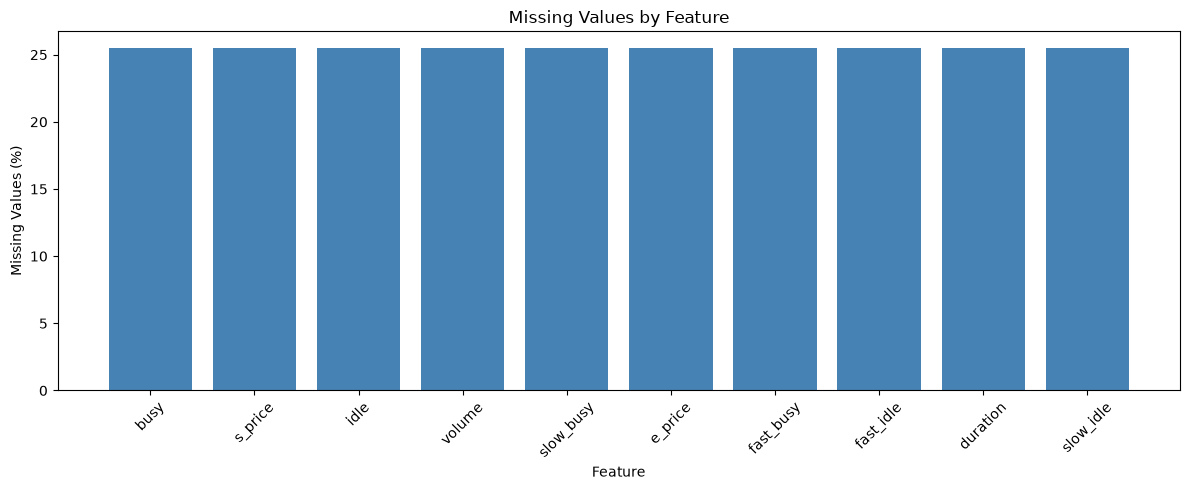

In [130]:
missing_plot = missing[
    missing["Missing Count"] > 0
]

plt.figure(figsize=(12, 5))

plt.bar(
    missing_plot.index,
    missing_plot["Missing Percentage"],
    color="steelblue"
)

plt.title("Missing Values by Feature")
plt.ylabel("Missing Values (%)")
plt.xlabel("Feature")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [131]:
station_missing = (
    df.groupby("station_id")["idle"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

display(station_missing.head(10))

print("Stations without missing data:",
      (station_missing == 0).sum())

print("Stations with over 30% missing data:",
      (station_missing > 30).sum())

print("Stations with over 50% missing data:",
      (station_missing > 50).sum())

print("Stations with completely missing data:",
      (station_missing == 100).sum())

station_id
1718    100.000000
1931     99.421296
1910     99.382716
1721     99.375000
1953     99.375000
1949     99.375000
1895     99.232253
1909     69.741512
1930     65.034722
1790     57.037037
Name: idle, dtype: float64

Stations without missing data: 44
Stations with over 30% missing data: 50
Stations with over 50% missing data: 10
Stations with completely missing data: 1


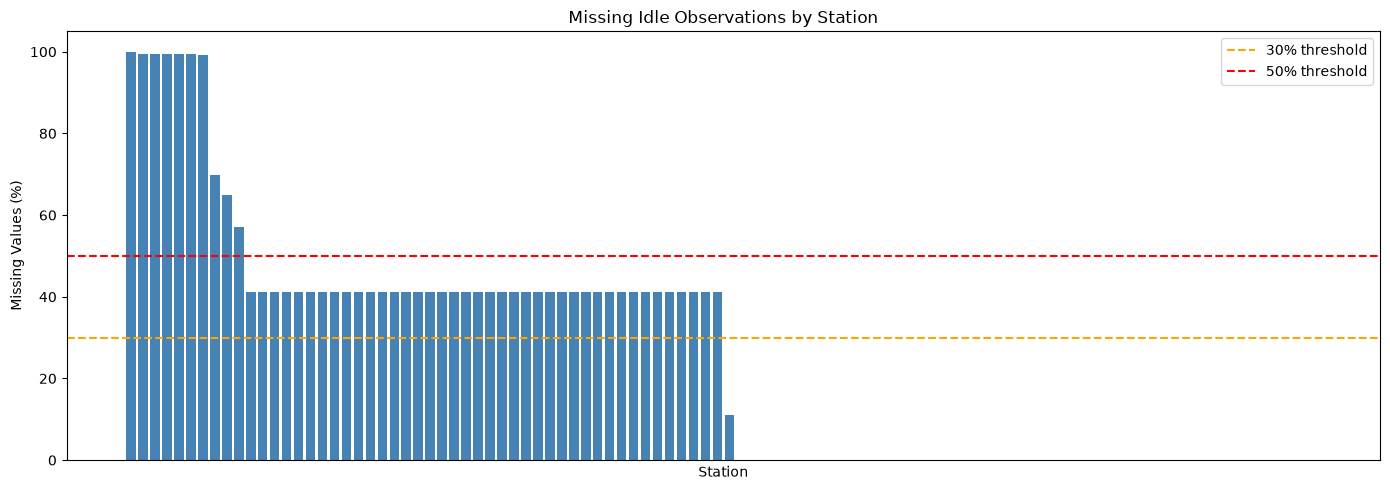

In [132]:
plt.figure(figsize=(14, 5))

plt.bar(
    station_missing.index.astype(str),
    station_missing.values,
    color="steelblue"
)

plt.axhline(
    y=30,
    color="orange",
    linestyle="--",
    label="30% threshold"
)

plt.axhline(
    y=50,
    color="red",
    linestyle="--",
    label="50% threshold"
)

plt.title("Missing Idle Observations by Station")
plt.xlabel("Station")
plt.ylabel("Missing Values (%)")
plt.xticks([])
plt.legend()
plt.tight_layout()
plt.show()

### 3.2. Station Availability Analysis

A charging station is considered available when at least
one charging point is idle.

- Available (1): idle > 0
- Fully occupied (0): idle = 0
- Unknown: missing idle observation

Missing observations are excluded from availability
rate calculations.

In [133]:
df["available"] = np.nan

df.loc[df["idle"] > 0, "available"] = 1
df.loc[df["idle"] == 0, "available"] = 0

print("Available observations:",
      (df["available"] == 1).sum())

print("Fully occupied observations:",
      (df["available"] == 0).sum())

print("Unknown observations:",
      df["available"].isna().sum())

Available observations: 1855333
Fully occupied observations: 76651
Unknown observations: 660016


In [134]:
station_availability = (
    df.groupby("station_id")
    .agg(
        capacity=("charge_count", "first"),
        total_observations=("available", "size"),
        valid_observations=("available", "count"),
        availability_rate=("available", "mean")
    )
)

station_availability["availability_rate"] *= 100

station_availability["fully_occupied_rate"] = (
    100 - station_availability["availability_rate"]
)

station_availability["missing_rate"] = (
    1 - station_availability["valid_observations"]
    / station_availability["total_observations"]
) * 100

display(station_availability.round(2))

,capacity,total_observations,valid_observations,availability_rate,fully_occupied_rate,missing_rate
station_id,,,,,,
1703,2,25920,15247,96.43,3.57,41.18
1712,6,25920,15247,99.70,0.30,41.18
1714,6,25920,25920,99.79,0.21,0.00
1717,17,25920,25915,99.71,0.29,0.02
1718,16,25920,0,NaN,NaN,100.00
...,...,...,...,...,...,...
1975,6,25920,25920,99.83,0.17,0.00
1980,24,25920,25920,99.82,0.18,0.00
1981,15,25920,25920,99.83,0.17,0.00


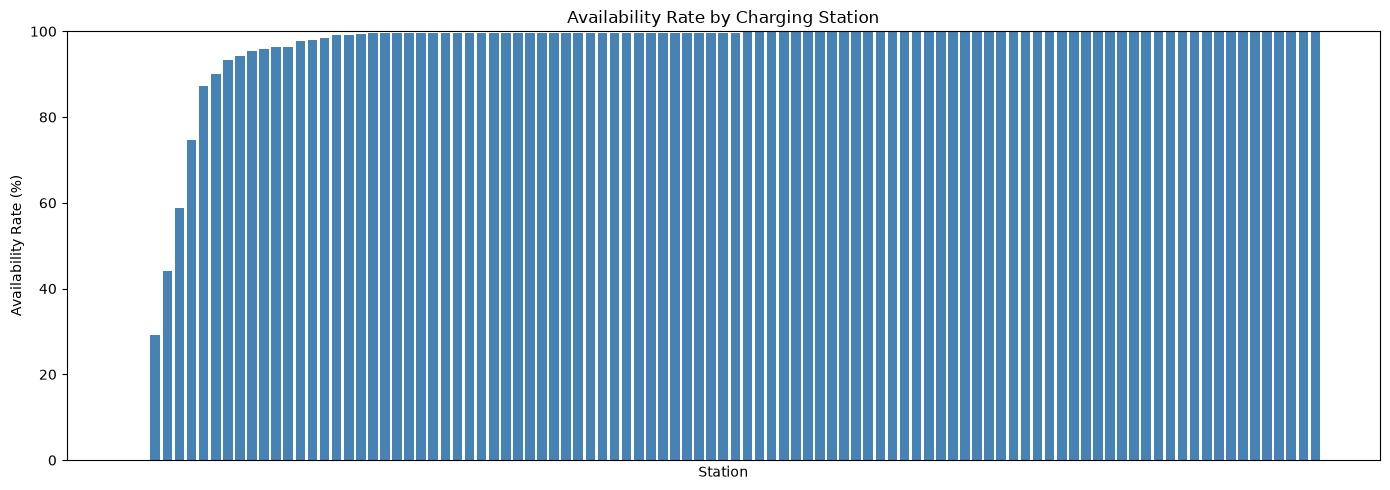

In [135]:
availability_sorted = (
    station_availability["availability_rate"]
    .dropna()
    .sort_values()
)

plt.figure(figsize=(14, 5))

plt.bar(
    availability_sorted.index.astype(str),
    availability_sorted.values,
    color="steelblue"
)

plt.title("Availability Rate by Charging Station")
plt.xlabel("Station")
plt.ylabel("Availability Rate (%)")
plt.ylim(0, 100)
plt.xticks([])
plt.tight_layout()
plt.show()

### 3.3. Target Distribution

This section examines the distribution of the binary
availability variable across all valid observations.

Missing observations are excluded from the distribution
to prevent artificial class labels.

In [136]:
target_counts = (
    df["available"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

target_distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_counts / target_counts.sum() * 100
})

target_distribution.index = [
    "Fully Occupied (0)",
    "Available (1)"
]

display(target_distribution.round(2))

,Count,Percentage
Fully Occupied (0),76651,3.97
Available (1),1855333,96.03


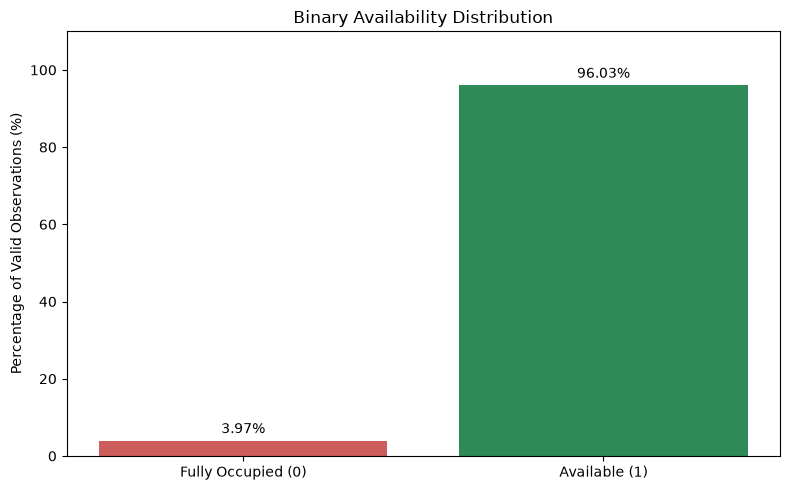

In [137]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    target_distribution.index,
    target_distribution["Percentage"],
    color=["indianred", "seagreen"]
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title("Binary Availability Distribution")
plt.ylabel("Percentage of Valid Observations (%)")
plt.ylim(0, 110)
plt.tight_layout()
plt.show()

### 3.4. Class Imbalance Analysis

The binary availability variable exhibits a significant
class imbalance. This analysis calculates the imbalance
ratio and the majority-class baseline accuracy.

In [138]:
majority_count = target_counts.max()
minority_count = target_counts.min()

imbalance_ratio = majority_count / minority_count

baseline_accuracy = (
    majority_count / target_counts.sum()
) * 100

print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")

print(
    f"Majority-class baseline accuracy: "
    f"{baseline_accuracy:.2f}%"
)

Imbalance ratio: 24.20:1
Majority-class baseline accuracy: 96.03%


**Key Findings**

- 96.03% of valid observations belong to the available class.
- Only 3.97% belong to the fully occupied class.
- The class imbalance ratio is 24.20:1.
- A majority-class classifier would achieve 96.03% accuracy
  without identifying any fully occupied stations.
- Accuracy alone is therefore insufficient for model evaluation.

### 3.5. Capacity-based Analysis

This section investigates the relationship between
charging station capacity and availability.

Stations are categorized into four capacity groups
to compare their availability and full occupancy rates.

In [139]:
station_availability["capacity_group"] = pd.cut(
    station_availability["capacity"],
    bins=[0, 5, 15, 30, np.inf],
    labels=["Small", "Medium", "Large", "Very Large"]
)

capacity_analysis = (
    station_availability
    .groupby("capacity_group", observed=True)
    .agg(
        number_of_stations=("capacity", "size"),
        stations_with_valid_data=("availability_rate", "count"),
        average_capacity=("capacity", "mean"),
        average_availability=("availability_rate", "mean"),
        average_full_occupancy=("fully_occupied_rate", "mean"),
        average_missing_rate=("missing_rate", "mean")
    )
)

display(capacity_analysis.round(2))

,number_of_stations,stations_with_valid_data,average_capacity,average_availability,average_full_occupancy,average_missing_rate
capacity_group,,,,,,
Small,42,42,2.95,91.83,8.17,21.37
Medium,36,36,8.81,99.71,0.29,20.90
Large,17,16,23.82,92.80,7.20,30.35
Very Large,5,5,44.00,99.94,0.06,76.11


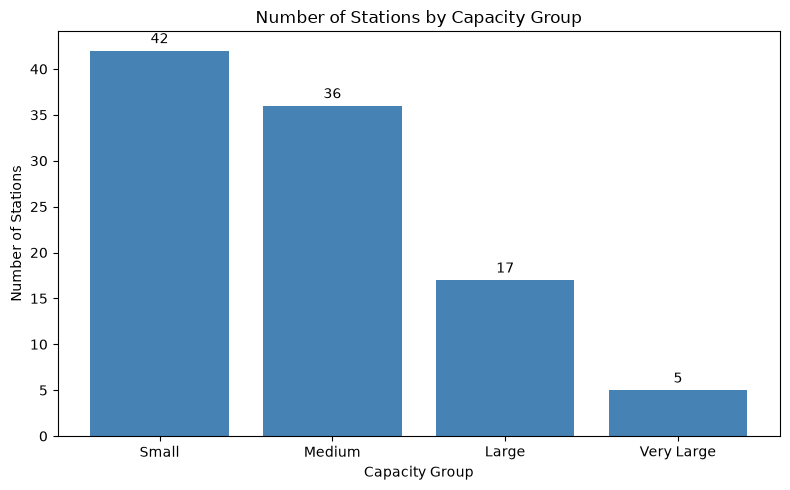

In [140]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    capacity_analysis.index,
    capacity_analysis["number_of_stations"],
    color="steelblue"
)

plt.bar_label(bars, padding=3)

plt.title("Number of Stations by Capacity Group")
plt.xlabel("Capacity Group")
plt.ylabel("Number of Stations")
plt.tight_layout()
plt.show()

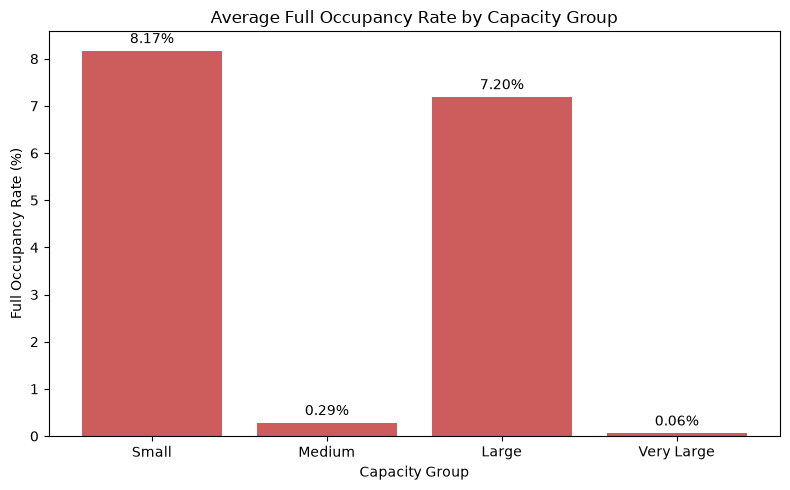

In [141]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    capacity_analysis.index,
    capacity_analysis["average_full_occupancy"],
    color="indianred"
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.title("Average Full Occupancy Rate by Capacity Group")
plt.xlabel("Capacity Group")
plt.ylabel("Full Occupancy Rate (%)")
plt.tight_layout()
plt.show()

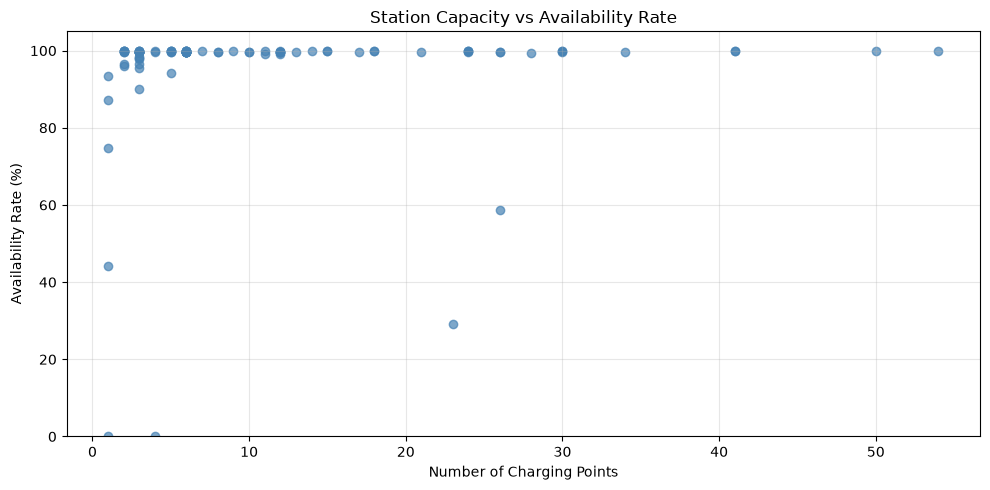

Pearson correlation: 0.0732


In [142]:
plt.figure(figsize=(10, 5))

plt.scatter(
    station_availability["capacity"],
    station_availability["availability_rate"],
    alpha=0.7,
    color="steelblue"
)

plt.title("Station Capacity vs Availability Rate")
plt.xlabel("Number of Charging Points")
plt.ylabel("Availability Rate (%)")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

correlation = station_availability[
    ["capacity", "availability_rate"]
].corr().iloc[0, 1]

print(f"Pearson correlation: {correlation:.4f}")

**Key Findings**

- Small stations represent 42% of the selected stations.
- Small stations have the highest average full occupancy
  rate (8.17%), followed by large stations (7.20%).
- Medium and very large stations exhibit higher observed
  availability rates.
- Very large stations have a high missing observation
  rate (76.11%), limiting the reliability of their results.
- Higher station capacity does not necessarily guarantee
  higher availability.

### 3.6. Busiest and Least Busy Stations

Stations are ranked according to their full occupancy
rates calculated from valid observations.

To improve ranking reliability, stations with more
than 50% missing observations are excluded from the
primary ranking but retained in the original dataset.

In [143]:
reliable_stations = station_availability[
    (station_availability["missing_rate"] <= 50)
    & (station_availability["valid_observations"] > 0)
].copy()

ranking_columns = [
    "capacity",
    "valid_observations",
    "availability_rate",
    "fully_occupied_rate",
    "missing_rate"
]

busiest = reliable_stations.nlargest(
    10, "fully_occupied_rate"
)[ranking_columns]

least_busy = reliable_stations.nsmallest(
    10, "fully_occupied_rate"
)[ranking_columns]

print("Stations included in primary ranking:",
      len(reliable_stations))

print("\nTop 10 Busiest Stations:")
display(busiest.round(2))

print("\nTop 10 Least Busy Stations:")
display(least_busy.round(2))

Stations included in primary ranking: 90

Top 10 Busiest Stations:


,capacity,valid_observations,availability_rate,fully_occupied_rate,missing_rate
station_id,,,,,
1882,4,15247,0.09,99.91,41.18
1775,1,15247,0.09,99.91,41.18
1758,1,25920,44.11,55.89,0.00
1763,1,25920,74.77,25.23,0.00
1751,1,15247,87.30,12.70,41.18
1888,3,25920,90.11,9.89,0.00
1778,1,15247,93.40,6.60,41.18
1879,5,25920,94.22,5.78,0.00
1797,3,25920,95.38,4.62,0.00



Top 10 Least Busy Stations:


,capacity,valid_observations,availability_rate,fully_occupied_rate,missing_rate
station_id,,,,,
1948,41,15256,99.96,0.04,41.14
1866,18,25920,99.85,0.15,0.00
1800,4,25920,99.84,0.16,0.00
1761,5,25920,99.84,0.16,0.00
1771,2,25920,99.84,0.16,0.00
1789,7,25920,99.84,0.16,0.00
1793,2,25920,99.84,0.16,0.00
1795,2,25920,99.84,0.16,0.00
1803,2,25920,99.84,0.16,0.00


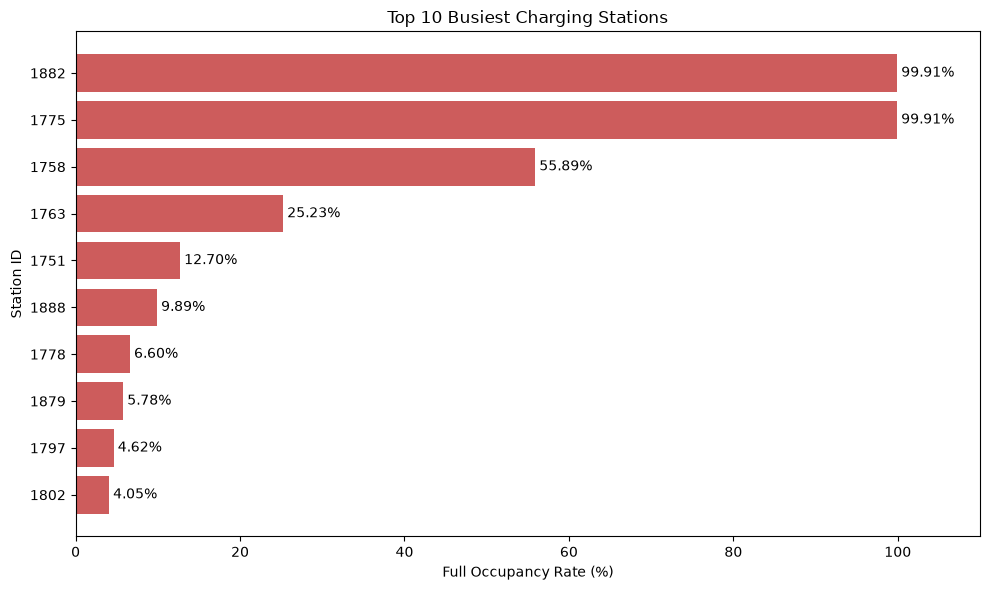

In [144]:
plt.figure(figsize=(10, 6))

bars = plt.barh(
    busiest.index.astype(str),
    busiest["fully_occupied_rate"],
    color="indianred"
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.gca().invert_yaxis()

plt.title("Top 10 Busiest Charging Stations")
plt.xlabel("Full Occupancy Rate (%)")
plt.ylabel("Station ID")
plt.xlim(0, 110)
plt.tight_layout()
plt.show()

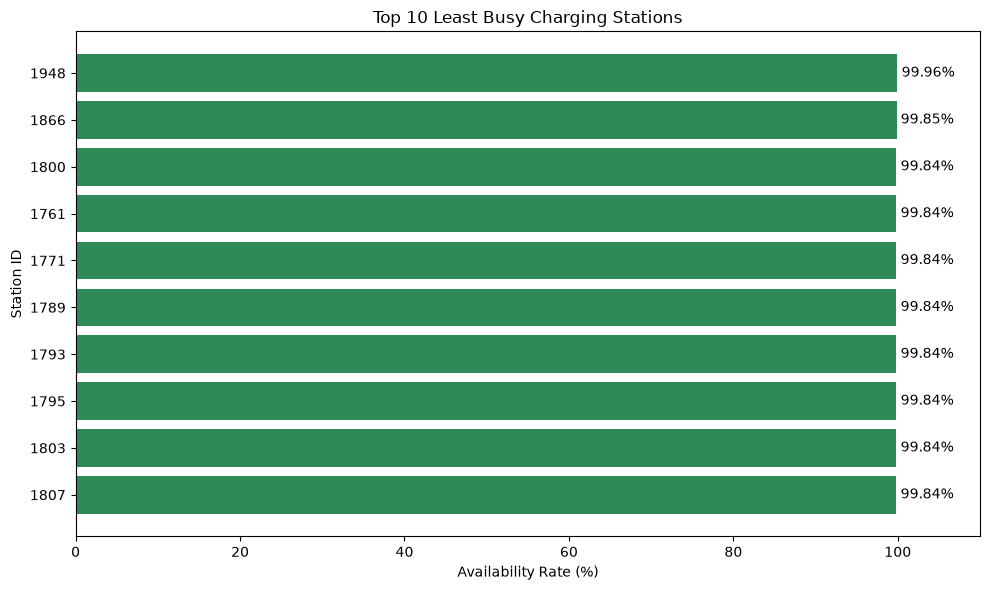

In [145]:
plt.figure(figsize=(10, 6))

bars = plt.barh(
    least_busy.index.astype(str),
    least_busy["availability_rate"],
    color="seagreen"
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.gca().invert_yaxis()

plt.title("Top 10 Least Busy Charging Stations")
plt.xlabel("Availability Rate (%)")
plt.ylabel("Station ID")
plt.xlim(0, 110)
plt.tight_layout()
plt.show()

In [146]:
print("Top 10 busiest stations without missing-rate filter:")

display(
    station_availability
    .dropna(subset=["fully_occupied_rate"])
    .nlargest(10, "fully_occupied_rate")
    [ranking_columns]
    .round(2)
)

Top 10 busiest stations without missing-rate filter:


,capacity,valid_observations,availability_rate,fully_occupied_rate,missing_rate
station_id,,,,,
1882,4,15247,0.09,99.91,41.18
1775,1,15247,0.09,99.91,41.18
1909,23,7843,29.15,70.85,69.74
1758,1,25920,44.11,55.89,0.00
1930,26,9063,58.81,41.19,65.03
1763,1,25920,74.77,25.23,0.00
1751,1,15247,87.30,12.70,41.18
1888,3,25920,90.11,9.89,0.00
1778,1,15247,93.40,6.60,41.18


### 3.7. Continuous Full Occupancy Duration

This analysis measures consecutive periods during which
charging stations remain fully occupied. Missing observations
interrupt continuous occupancy periods.

Average duration: 172.72 minutes
Median duration: 10.00 minutes
Maximum duration: 74975.00 minutes


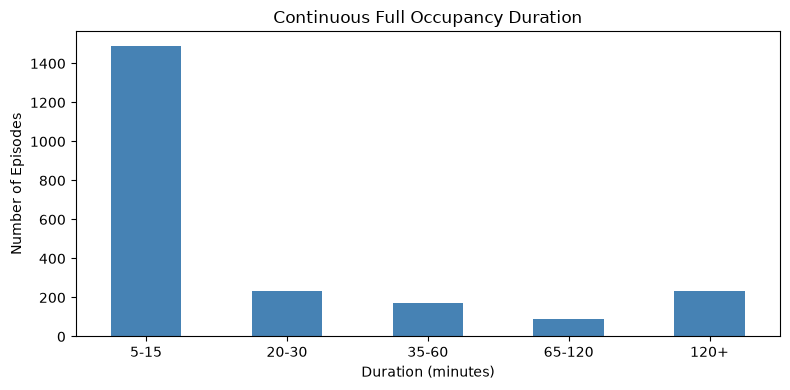

In [147]:
temp = df[["station_id", "time", "available"]].copy()
temp = temp.sort_values(["station_id", "time"])

full = temp["available"].eq(0)

groups = (
    temp["station_id"].ne(temp["station_id"].shift())
    | full.ne(full.shift())
    | temp["time"].diff().ne(pd.Timedelta(minutes=5))
).cumsum()

duration = temp[full].groupby(groups[full]).size() * 5

print(f"Average duration: {duration.mean():.2f} minutes")
print(f"Median duration: {duration.median():.2f} minutes")
print(f"Maximum duration: {duration.max():.2f} minutes")

bins = [0, 15, 30, 60, 120, np.inf]
labels = ["5-15", "20-30", "35-60", "65-120", "120+"]

counts = pd.cut(duration, bins=bins, labels=labels).value_counts().sort_index()

counts.plot(kind="bar", color="steelblue", figsize=(8, 4))

plt.title("Continuous Full Occupancy Duration")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Episodes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Conclusion

- The analysis covers 100 charging stations and
  2,592,000 observations.
- 25.46% of observations contain missing availability data.
- Among valid observations, 96.03% are available and
  3.97% are fully occupied.
- The class imbalance ratio is 24.20:1, indicating
  that accuracy alone is insufficient for model evaluation.
- Availability varies considerably across stations
  and capacity groups.
- The median continuous full occupancy duration
  is 10 minutes.
- Extremely long occupancy periods may indicate
  data quality issues.

In [ ]:
TABLE_DIR = ROOT / "outputs" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

station_availability.to_csv(
    TABLE_DIR / "station_availability.csv"
)

target_distribution.to_csv(
    TABLE_DIR / "target_distribution.csv"
)

capacity_analysis.to_csv(
    TABLE_DIR / "capacity_analysis.csv"
)

print("Tables saved successfully.")